# #267 Historical Nowscore/Titan backfill PoC

This executed notebook reviews the complete known Beijing issue × fixture denominator, reconciles stale local-cache rows against the authoritative Nowscore issue-page matrix, and tests Titan initial/10h/1h retention. It is a read-only acquisition assessment: it does not publish or mutate the accepted #236 package.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    raise RuntimeError('execute from repository root')
data_root = os.environ.get('BEIJING_LOT_DATA_ROOT')
if not data_root:
    raise RuntimeError('BEIJING_LOT_DATA_ROOT is required')
DATA_ROOT = Path(data_root).resolve()
RESULTS = ROOT / 'results' / 'bj267_eu_proxy_backfill_poc_v3'
report = json.loads((RESULTS / 'COVERAGE_REPORT.json').read_text())
extension_parity = json.loads((RESULTS / 'EXTENSION_NORMALIZED_PARITY.json').read_text())
STAGING = DATA_ROOT / 'staging' / report['staging_namespace']
probes = pd.read_csv(RESULTS / 'ISSUE_PROBE_RESULTS.csv', dtype={'issue_code': str})
titan = pd.read_csv(RESULTS / 'TITAN_SAMPLE_RESULTS.csv', dtype={'issue_code': str})
source_counts = pd.read_csv(RESULTS / 'RECONCILED_SOURCE_COUNTS.csv')
exclusions = pd.read_csv(RESULTS / 'LOCAL_CACHE_EXCLUSIONS.csv', dtype={'issue_code': str})
local_only = pd.read_parquet(STAGING / 'LOCAL_ONLY_SLOTS.parquet')
reconciled = pd.read_parquet(STAGING / 'RECONCILED_ISSUE_FIXTURE_INVENTORY.parquet')
assert report['decision'] == 'FULL_BACKFILL_EXECUTABLE'
assert report['protected_source_sha256_before'] == report['protected_source_sha256_after']
assert report['canonical_write_performed'] is False
report['decision'], report['execution_mode']

('FULL_BACKFILL_EXECUTABLE', 'REPLAY')

## Reconciled denominator

The original local union contained 215,193 rows, but `beidan_live.db` carries rows from the preceding issue during issue transitions. Nowscore's embedded `M[row][field]` matrix is used for complete issue membership, including settled/cancelled rows omitted from the visible HTML table.

In [2]:
summary = pd.DataFrame([
    ('local candidate union', report['inventory']['known_fixture_count']),
    ('accepted #236', report['inventory']['accepted_236_fixture_count']),
    ('existing 2026 extension', report['inventory']['extension_fixture_count']),
    ('recovered from 73 issue pages', report['source_recovered_fixture_count']),
    ('excluded stale local-cache rows', report['local_cache_excluded_fixture_count']),
    ('reconciled target', report['reconciled_fixture_count']),
], columns=['component', 'fixture_count'])
display(summary)
display(source_counts)
assert reconciled.issue_code.nunique() == 808
assert len(reconciled) == 213263
assert len(local_only) == 1930

,component,fixture_count
0,local candidate union,215193
1,accepted #236,192709
2,existing 2026 extension,6001
3,recovered from 73 issue pages,14553
4,excluded stale local-cache rows,1930
5,reconciled target,213263


,reconciled_source,issue_count,fixture_count
0,ACCEPTED_236,701,192709
1,AVAILABLE_EXTENSION,34,6001
2,NOWSCORE_ISSUE_PAGE,73,14553


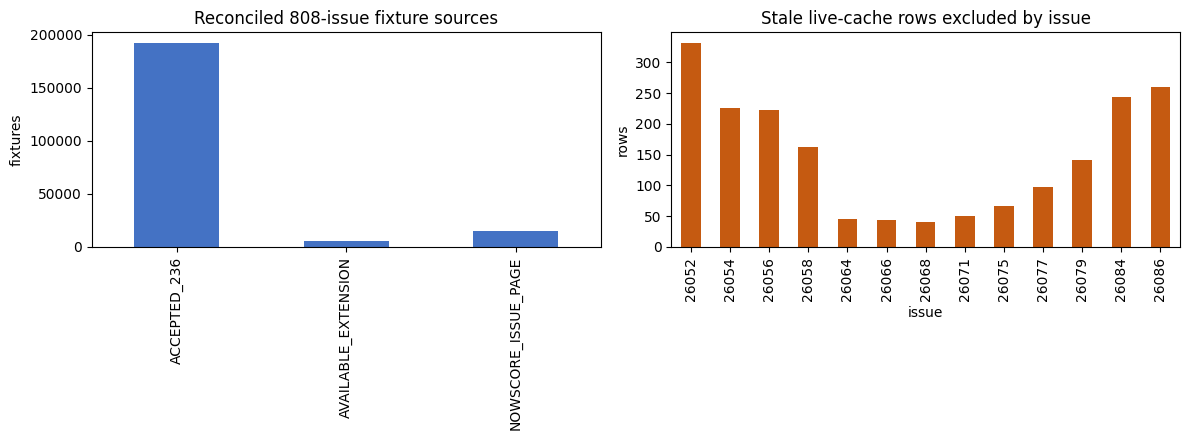

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
source_counts.plot.bar(x='reconciled_source', y='fixture_count', legend=False, ax=axes[0], color='#4472C4')
axes[0].set_title('Reconciled 808-issue fixture sources')
axes[0].set_xlabel('')
axes[0].set_ylabel('fixtures')
exclusions.plot.bar(x='issue_code', y='local_only_slot_count', legend=False, ax=axes[1], color='#C55A11')
axes[1].set_title('Stale live-cache rows excluded by issue')
axes[1].set_xlabel('issue')
axes[1].set_ylabel('rows')
plt.tight_layout()
figure_path = RESULTS / 'coverage_reconciliation.png'
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.show()

## Source availability and horizon retention

All 73 unresolved issue pages yielded authoritative membership and provider IDs for 14,553 fixtures. One Titan history was tested per issue; retry-protected acquisition succeeded for all 73, and every sample contained at least one complete initial/10h/1h bookmaker triplet. The existing 34-issue extension is separately checked for #236 source-schema parity.

In [4]:
probe_summary = pd.DataFrame({
    'metric': ['issues probed', 'source fixtures', 'source-only slots', 'local-only stale slots', 'Titan samples available'],
    'value': [len(probes), probes.source_fixture_count.sum(), probes.source_only_slot_count.sum(), probes.local_only_slot_count.sum(), titan.status.eq('AVAILABLE').sum()],
})
display(probe_summary)
horizons = pd.DataFrame(report['extension_profile']['horizon_counts'])
horizons['complete_rate'] = horizons.complete_rows / horizons.raw_rows
display(horizons)
display(pd.DataFrame([extension_parity['domain_checks']]))
display(pd.DataFrame([{k: extension_parity[k] for k in ['schema_parity', 'domain_parity', 'matched_fixture_count', 'unmatched_fixture_count', 'probability_rows', 'strict_forward_rows']}]))
display(pd.DataFrame(extension_parity['unmatched_fixture_dispositions']))
assert probes.status.eq('AUTHORITATIVE_ISSUE_MEMBERSHIP_AVAILABLE').all()
assert titan.status.eq('AVAILABLE').all()
assert report['extension_profile']['schema_compatible'] is True
assert extension_parity['schema_parity'] is True
assert extension_parity['domain_parity'] is True
assert extension_parity['strict_forward_rows'] == 0

,metric,value
0,issues probed,73
1,source fixtures,14553
2,source-only slots,0
3,local-only stale slots,1930
4,Titan samples available,73


,complete_rows,market,raw_rows,snapshot,complete_rate
0,75981,euro_1x2,90015,initial,0.844093
1,75734,euro_1x2,90015,10h,0.841349
2,75933,euro_1x2,90015,1h,0.843559


,availability_mask_one,causal_grade_retrospective_proxy,horizons_initial_10h_1h,market_euro_1x2,outcome_codes_3_1_0,probability_range,probability_triplets_sum_one,source_role_nowscore_titan
0,True,True,True,True,True,True,True,True


,schema_parity,domain_parity,matched_fixture_count,unmatched_fixture_count,probability_rows,strict_forward_rows
0,True,True,6000,1,54000,0


,canonical_fixture_key,disposition,issue_code,match_idx,provider_match_id
0,bjslot:26051:331,UNAVAILABLE_NO_VALID_EURO_1X2_HORIZON,26051,331,2924541


## Decision and #268 handoff

**FULL_BACKFILL_EXECUTABLE.** #268 should ingest the accepted #236 package, the schema-compatible 34-issue extension, and all 14,553 recovered issue-page fixtures into a new immutable version. The full crawl must remain resumable and hash-bound, record unavailable bookmaker/horizon cells explicitly, normalize through the frozen #236 de-vig path, and promote atomically only after validation. The 1,930 stale live-cache rows are exclusions, not missing fixtures. No result, winning SP, payout, or 0.65 field was selected here.